# Modèle de rendement — classement servi, modèle final et interprétation métier

Le notebook 09 a retenu `ExtraTrees` et montré qu'il classe bien — en rendement brut. Reste
à transformer un modèle en **service utilisable**, ce qui pose cinq problèmes distincts :

1. **Un classement en tonnes brutes n'a pas de sens entre cultures.** Il placerait un
   tubercule en tête presque partout, et le service répondrait « pomme de terre » quelles
   que soient les conditions.
2. **Le classement servi doit être mesuré pour lui-même.** Le notebook 09 a mesuré l'ordre
   en tonnes brutes sur dix cultures ; l'utilisateur verra un autre ordre, sur d'autres
   cultures.
3. **Le sujet demande la culture la plus rentable.** Aucun des deux jeux ne contient de prix :
   il faut une source externe, et dire ce qu'elle permet et ne permet pas.
4. **Le modèle servi doit tenir dans le dépôt.** Une forêt n'est pas un fichier léger.
5. **Il faut dire ce que le modèle sait, et ce qu'il ne sait pas.**

Puis l'évaluation finale sur 2013, touchée une seule fois.

# Imports

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.ensemble import ExtraTreesRegressor
from sklearn.inspection import permutation_importance

sys.path.insert(0, str(Path.cwd().parent))

from src import config, tracking, utils
from src.data import prices as fao_prices
from src.models import evaluation, features, protocol
from src.models import yield_model as ym

utils.style()
np.random.seed(config.SEED)
tracking.configure(tracking.EXPERIMENT_YIELD)

df = ym.load()
print(f"{len(df):,} lignes | {df.iso3.nunique()} pays | {df.crop.nunique()} cultures")

# FAOSTAT producer prices, built by `make data-prices`.
prices = fao_prices.load()
print(f"prix producteurs : {len(prices):,} valeurs | {prices.iso3.nunique()} pays")

15,605 lignes | 117 pays | 10 cultures
prix producteurs : 12,915 valeurs | 159 pays


# 1. Le problème du classement en tonnes brutes

Les dix cultures du jeu n'ont pas des rendements comparables : la pomme de terre rend
environ 16 t/ha, le sorgho 1,3 t/ha. Mais une part considérable de l'écart est de **l'eau**.

In [2]:
folds = protocol.temporal_cv(df["year"], ym.VALIDATION_YEARS)
model = ym.selected_model(n_trees=200)
predictions = evaluation.out_of_fold_predictions(
    model, df[ym.VARIABLES], df[features.YIELD_TARGET], folds)
evaluated = df.loc[predictions.index].assign(prediction=predictions)

# Which crop does the model rank first, depending on the measure used?
import collections
n1_raw, n1_dry = collections.Counter(), collections.Counter()
for _, block in evaluated.groupby(["iso3", "year"]):
    n1_raw[block.loc[block["prediction"].idxmax(), "crop"]] += 1
    dry = block["prediction"] * block["crop"].map(features.DRY_MATTER)
    n1_dry[block.loc[dry.idxmax(), "crop"]] += 1

comparison = pd.DataFrame({"tonnes brutes": n1_raw, "matière sèche": n1_dry}).fillna(0).astype(int)
comparison["group"] = comparison.index.map(features.CROP_GROUP)
comparison.sort_values("tonnes brutes", ascending=False)

,tonnes brutes,matière sèche,group
Potatoes,412,147,tubercule
Cassava,73,100,tubercule
Sweet potatoes,39,42,tubercule
Yams,33,23,tubercule
Plantains and others,14,27,tubercule
Sorghum,5,12,cereale
Maize,4,130,cereale
"Rice, paddy",0,79,cereale
Wheat,0,20,cereale


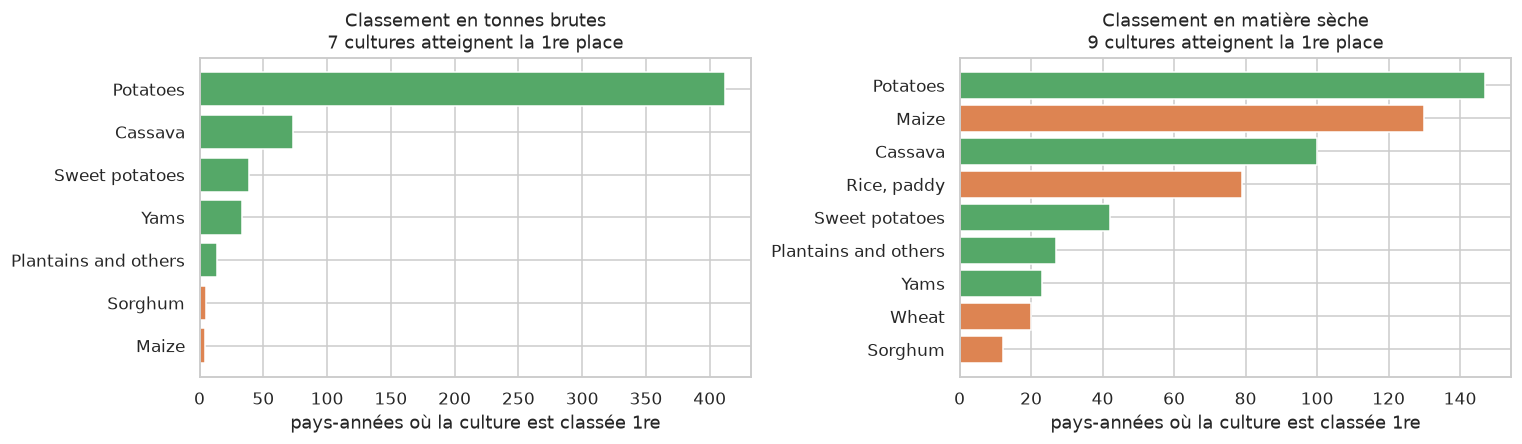

cultures atteignant la 1re place — en tonnes brutes : 7
cultures atteignant la 1re place — en matière sèche : 9

part des 1res places tenues par un tubercule :
   tonnes brutes : 98.4%
   matière sèche : 58.4%


In [3]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.2))
for ax, (column, title) in zip(axes, [("tonnes brutes", "Classement en tonnes brutes"),
                                       ("matière sèche", "Classement en matière sèche")]):
    frame = comparison[comparison[column] > 0].sort_values(column, ascending=True)
    colours = {"cereale": "#DD8452", "tubercule": "#55A868", "oleoproteagineux": "#4C72B0"}
    ax.barh(frame.index, frame[column],
            color=[colours[g] for g in frame["group"]])
    ax.set_title(f"{title}\n{(frame[column] > 0).sum()} cultures atteignent la 1re place")
    ax.set_xlabel("pays-années où la culture est classée 1re")
utils.save_figure("10_classement_brut_vs_seche")
plt.show()

print(f"cultures atteignant la 1re place — en tonnes brutes : {(comparison['tonnes brutes'] > 0).sum()}")
print(f"cultures atteignant la 1re place — en matière sèche : {(comparison['matière sèche'] > 0).sum()}")
tuber_share = comparison.loc[
    comparison.group == "tubercule", ["tonnes brutes", "matière sèche"]].sum() / len(evaluated.groupby(["iso3","year"]))
print(f"\npart des 1res places tenues par un tubercule :")
print(f"   tonnes brutes : {tuber_share['tonnes brutes']:.1%}")
print(f"   matière sèche : {tuber_share['matière sèche']:.1%}")

**Observations — le défaut est réel, et mesuré :**

- **En tonnes brutes, les tubercules monopolisent la première place.** Très peu de cultures
  y accèdent, et un service qui répondrait cela serait inutile : il donnerait presque toujours
  la même réponse, indépendamment des conditions saisies.
- La cause est agronomique, pas statistique : une pomme de terre est à **79 % d'eau**, un
  grain de blé à **13 %**. Comparer leurs tonnages revient à comparer des choses
  différentes.
- **Ramené en matière sèche, le classement s'ouvre** : nettement plus de cultures accèdent à
  la première place, et les céréales y apparaissent.

La table de teneurs est dans `src/models/features.py`. Elle sert à **ordonner**, pas à
calculer une valeur nutritionnelle.

## Deuxième garde-fou : les cultures jamais cultivées dans le pays

Le modèle peut placer en tête une culture que le pays n'a jamais produite. Rien dans la
validation ne mesure ce cas — toutes les lignes évaluées portent sur des couples
pays × culture déjà observés. C'est donc une **extrapolation non mesurée**, qu'il faut
signaler.

In [4]:
# Beware of the measurement trap: ranking only the crops present in a country's
# data would give 0 % by construction. All 10 crops must be ranked, as the
# service will do, then check whether the first one is actually grown there.
X_train_m, _, y_train_m, _ = protocol.temporal_split(
    df, ym.VARIABLES, features.YIELD_TARGET)
measured_model = ym.selected_model(150).fit(X_train_m, y_train_m)

outside_raw = outside_dry = 0
countries = sorted(df["iso3"].unique())
for iso3 in countries:
    context = ym.country_context(df, iso3)
    table = ym.ranking(measured_model, context, ym.crops_of_country(df, iso3),
                          product_crops=False)
    outside_dry += not table.iloc[0]["observed"]
    outside_raw += not table.sort_values("raw_yield_t_ha", ascending=False).iloc[0]["observed"]

print(f"1res places portant sur une culture jamais observée dans le pays, sur {len(countries)} pays :")
print(f"   en tonnes brutes : {outside_raw:3d} ({outside_raw/len(countries):.1%})")
print(f"   en matière sèche : {outside_dry:3d} ({outside_dry/len(countries):.1%})")

1res places portant sur une culture jamais observée dans le pays, sur 117 pays :
   en tonnes brutes :  28 (23.9%)
   en matière sèche :  37 (31.6%)


**Observations :** environ un quart à un tiers des premières places porte sur une culture
que le pays n'a **jamais produite**. Le modèle extrapole alors sur un terrain que la
validation ne couvre pas du tout.

Et la normalisation en matière sèche **aggrave** ce point : en ouvrant le classement à des
cultures que le tonnage brut écartait, elle propose plus souvent une culture non pratiquée
localement. Les deux corrections ne vont donc pas dans le même sens, et il faut les traiter
ensemble. Deux réponses, toutes deux implémentées :

- le classement rendu porte une colonne **`observed`** ;
- le **top 3** est présenté plutôt que la seule première place — la section suivante mesure
  ce qu'il vaut sur le classement réellement servi.

# 2. Le classement servi, mesuré pour lui-même

Le notebook 09 a mesuré la qualité du classement **en tonnes brutes, sur les dix cultures FAO**.
Ce n'est pas ce que voit l'utilisateur. Le service classe :

- en **matière sèche** (section 1), ou en **produit brut** (section 3) ;
- sur les **quatre cultures de l'application** présentes dans le jeu FAO : maïs, blé, riz,
  soja. L'orge et le coton en sont **exclus** : absents du jeu FAO, ils n'auraient qu'un rang
  recopié de leur culture donneuse (blé et sorgho). Ils ne sont ni estimés ni classés.

Chaque vue est donc mesurée séparément, avec la même conversion appliquée au rendement observé
et au rendement prédit, sur les mêmes prédictions hors apprentissage (validation 2008-2012).
La référence reste le classement figé par rendement médian passé.

Aux trois mesures d'ordre s'ajoute ce que coûte une erreur : la **perte relative**, c'est-à-dire
l'écart entre la meilleure culture observée et celle classée première, rapporté à la meilleure.
En produit brut, c'est la part du chiffre d'affaires perdue en suivant le classement : la
« précision économique » demandée par le sujet.

In [5]:
medians = df[df.year < min(ym.VALIDATION_YEARS)].groupby("crop")[features.YIELD_TARGET].median()
naive = evaluated["crop"].map(medians)

model_quality = ym.quality_by_view(evaluated, evaluated["prediction"], prices)
naive_quality = ym.quality_by_view(evaluated, naive, prices)

views = pd.DataFrame([
    {
        "vue": ym.VIEWS[view],
        "top1 modèle": model_quality[view]["top1"],
        "top1 figé": naive_quality[view]["top1"],
        "top3 modèle": model_quality[view]["top3"],
        "Spearman modèle": model_quality[view]["spearman"],
        "Spearman figé": naive_quality[view]["spearman"],
        "perte relative modèle": model_quality[view]["relative_regret"],
        "perte relative figé": naive_quality[view]["relative_regret"],
        "pays-années": model_quality[view]["groups"],
    }
    for view in ym.VIEWS
]).set_index("vue")
views.round(3)

,top1 modèle,top1 figé,top3 modèle,Spearman modèle,Spearman figé,perte relative modèle,perte relative figé,pays-années
vue,,,,,,,,
"10 cultures FAO, rendement brut (t/ha)",0.934,0.744,0.998,0.964,0.847,0.008,0.086,575
"10 cultures FAO, matière sèche (t/ha)",0.821,0.360,0.981,0.920,0.581,0.024,0.213,575
"4 cultures de l'application, matière sèche (t/ha)",0.916,0.647,0.998,0.922,0.717,0.015,0.113,524
"10 cultures FAO, produit brut (USD/ha)",0.932,0.828,1.000,0.957,0.775,0.011,0.059,575
"4 cultures de l'application, produit brut (USD/ha)",0.926,0.649,0.998,0.897,0.416,0.013,0.118,524


**Observations — le classement servi, mesuré pour lui-même :**

- **Le chiffre du notebook 09 surestimait ce que voit l'utilisateur.** Sur les dix cultures, le
  modèle trouve la meilleure culture en tête dans 93 % des cas en tonnes brutes, mais
  **82 % en matière sèche**. C'est logique : en matière sèche, les écarts entre cultures se
  resserrent et l'ordre devient plus difficile.
- **Sur le périmètre réellement servi — les quatre cultures de l'application —, la première
  place est juste dans 92 % des cas en matière sèche, 93 % en produit brut.** Le top 3, en
  revanche, n'apporte plus rien ici : sur quatre cultures, il est juste par construction ou
  presque. Ce sont la corrélation de rang (≈ 0,9) et la perte qui renseignent.
- **Le modèle bat nettement l'ordre figé, dans toutes les vues.** En produit brut sur les
  quatre cultures, suivre le modèle coûte en moyenne **1,3 %** du produit brut de la meilleure
  culture, contre **11,8 %** pour un ordre figé. C'est la « précision économique » demandée par
  le sujet : se tromper de première culture arrive, mais rarement de beaucoup.
- Rappel de portée : ces mesures portent sur les couples pays × culture **réellement observés**
  (validation 2008-2012). Elles ne disent rien des cultures jamais pratiquées dans le pays.

# 3. Lecture économique : le produit brut

Le sujet demande « la culture la plus rentable ». Aucun des deux jeux ne contient de variable
économique. Une troisième source, gratuite et documentée, comble en partie ce manque : les
**prix au producteur FAOSTAT** (USD par tonne, par pays, culture et année), préparés par
`src/data/prix.py`.

- **Produit brut** = rendement prédit × prix au producteur : ce que la récolte rapporte à la
  sortie de la ferme, en USD/ha.
- Prix du pays = médiane de ses 5 dernières années connues, **jamais postérieures** à l'année
  du contexte ; à défaut, médiane mondiale, signalée dans `price_source`.
- **Ce n'est pas une marge** : les coûts de production sont inconnus. Une pomme de terre se vend
  plus cher à l'hectare que du blé, mais coûte aussi bien plus à produire. Le service dit
  « produit brut », jamais « bénéfice ».

Deux questions : le classement change-t-il quand on passe de la matière sèche au produit brut,
et tient-il si les prix varient ?

In [6]:
import collections

rng = np.random.default_rng(config.SEED)
DRAWS, PRICE_SPREAD = 500, 0.20   # prices drawn around their reference, ~ +-20 % (log-normal)
FOUR_CROPS = set(ym.PRODUCT_TO_FAO.values())

stability = {"10 cultures FAO": [], "4 cultures de l'application": []}
n1_economic, disagreements, country_prices = collections.Counter(), 0, []
n1_detail = collections.Counter()
for iso3 in countries:
    context = ym.country_context(df, iso3)
    table = ym.ranking(measured_model, context, ym.crops_of_country(df, iso3),
                          product_crops=False, prices=prices, criterion="gross_product_usd_ha")
    first = table.iloc[0]
    n1_economic[first["crop"]] += 1
    n1_detail[(first["crop"],
               "cultivée dans le pays" if first["observed"] else "jamais cultivée",
               first["price_source"])] += 1
    n1_dry = table.sort_values("dry_matter_t_ha", ascending=False).iloc[0]["crop"]
    disagreements += table.iloc[0]["crop"] != n1_dry
    country_prices.append((table["price_source"] == fao_prices.SOURCE_COUNTRY).mean())

    # The model's yields are fixed; only prices are drawn. Is the first place unchanged?
    for name, below in (("10 cultures FAO", table),
                      ("4 cultures de l'application", table[table["crop"].isin(FOUR_CROPS)])):
        product = below["gross_product_usd_ha"].to_numpy()
        draws = product * rng.lognormal(0.0, PRICE_SPREAD, size=(DRAWS, len(product)))
        stability[name].append(float((draws.argmax(axis=1) == product.argmax()).mean()))

n1 = pd.Series(n1_economic, name="pays").sort_values(ascending=False).to_frame()
n1["group"] = n1.index.map(features.CROP_GROUP)
print(f"pays : {len(countries)} | prix du pays lui-même : {np.mean(country_prices):.0%} des cultures, "
      "médiane mondiale pour le reste")
print(f"1re place différente entre matière sèche et produit brut : {disagreements} pays "
      f"({disagreements / len(countries):.0%})")
print(f"part des 1res places en produit brut tenues par un tubercule : "
      f"{n1.loc[n1.group == 'tubercule', 'pays'].sum() / len(countries):.0%}\n")
print(n1.to_string())
print("\n1re place en produit brut, détaillée :")
print(pd.Series(n1_detail, name="pays").sort_values(ascending=False)
      .rename_axis(["crop", "dans le pays", "prices"]).to_string())
print()
for name, values in stability.items():
    values = np.array(values)
    print(f"{name:28} 1re place inchangée sous ±20 % de prix : médiane {np.median(values):.0%} "
          f"| pays stables à 90 % ou plus : {(values >= 0.9).mean():.0%}")

pays : 117 | prix du pays lui-même : 43% des cultures, médiane mondiale pour le reste
1re place différente entre matière sèche et produit brut : 101 pays (86%)
part des 1res places en produit brut tenues par un tubercule : 100%

                      pays      group
Yams                    84  tubercule
Potatoes                27  tubercule
Sweet potatoes           4  tubercule
Cassava                  1  tubercule
Plantains and others     1  tubercule

1re place en produit brut, détaillée :
crop                  dans le pays           prices          
Yams                  jamais cultivée        médiane mondiale    68
Potatoes              cultivée dans le pays  pays                25
Yams                  cultivée dans le pays  médiane mondiale     9
                                             pays                 5
Sweet potatoes        cultivée dans le pays  pays                 4
Yams                  jamais cultivée        pays                 2
Potatoes              jamais cult

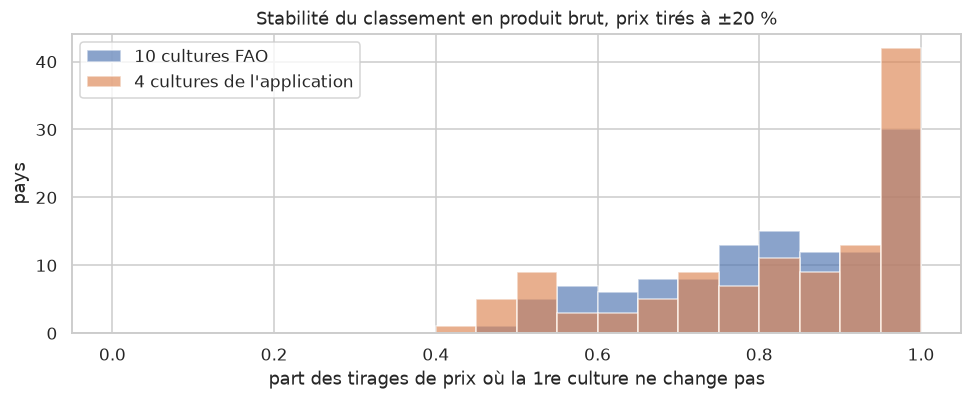

In [7]:
fig, ax = plt.subplots(figsize=(9, 3.8))
for (name, values), colour in zip(stability.items(), ["#4C72B0", "#DD8452"]):
    ax.hist(values, bins=np.linspace(0, 1, 21), alpha=0.65, color=colour, label=name)
ax.set_xlabel("part des tirages de prix où la 1re culture ne change pas")
ax.set_ylabel("pays")
ax.set_title("Stabilité du classement en produit brut, prix tirés à ±20 %")
ax.legend()
utils.save_figure("10_sensibilite_prix")
plt.show()

**Observations — le produit brut répond à la question du sujet, mais pas sur dix cultures :**

- **Sur les dix cultures FAO, le produit brut aggrave le problème des tubercules au lieu de le
  régler.** Toutes les premières places reviennent à un tubercule, et l'**igname** est en tête
  dans 84 pays sur 117 — dont **68 qui n'en ont jamais cultivé**, évaluée au **prix médian
  mondial** faute de prix local. Ce prix est le plus élevé des dix cultures (≈ 770 USD/t), et le
  rendement est une extrapolation. Deux incertitudes se multiplient : ce classement n'est pas
  servable.
- **Sur les quatre cultures de l'application, le classement est plausible** et les prix sont
  plus souvent ceux du pays : en France, maïs, puis riz, blé et soja. C'est le périmètre à
  servir.
- **Le critère change la réponse.** La première place diffère entre matière sèche et produit
  brut dans 86 % des pays (sur dix cultures). L'interface doit dire sur quel critère elle classe,
  et laisser le choix.
- **Le classement économique est fragile face aux prix.** Prix tirés à ±20 % autour de leur
  référence, la première des quatre cultures reste la même dans 87 % des tirages en médiane,
  mais **seuls 47 % des pays** sont stables dans au moins 90 % des tirages. Pour un pays sur
  deux, l'écart de produit brut entre les deux premières cultures est plus petit que
  l'incertitude sur les prix.

**Décisions pour le service :**

1. le produit brut est calculé sur **les quatre cultures de l'application**, jamais sur dix ;
2. les prix sont **affichés et modifiables** : l'agriculteur connaît mieux son prix de vente
   que la médiane FAOSTAT ;
3. le service présente les **deux ou trois premières** cultures, pas une seule ;
4. il dit « **produit brut** », jamais « bénéfice » ni « rentabilité » : les coûts restent
   inconnus.

# 4. Taille du modèle servi

Une forêt stocke tous ses arbres. Le fichier doit rester sous la limite de 50 Mo par fichier
de GitHub, et se charger rapidement au démarrage de l'API.

In [8]:
sizes = []
for n_trees in (50, 100, 150, 200, 300):
    candidate = ym.selected_model(n_trees)
    candidate_folds = evaluation.validate_by_fold(
        candidate, df[ym.VARIABLES], df[features.YIELD_TARGET], folds)
    metrics = evaluation.summarise(candidate_folds)
    X_train, _, y_train, _ = protocol.temporal_split(
        df, ym.VARIABLES, features.YIELD_TARGET)
    fitted = candidate.fit(X_train, y_train)
    sizes.append({
        "arbres": n_trees,
        "RMSE CV": metrics["cv_rmse_mean"],
        "MAE CV": metrics["cv_mae_mean"],
        "taille lzma (Mo)": ym.compressed_size(fitted),
    })
sizes = pd.DataFrame(sizes)
sizes.round(4)

,arbres,RMSE CV,MAE CV,taille lzma (Mo)
0,50,1.4597,0.7286,13.0367
1,100,1.4553,0.7270,26.0295
2,150,1.4514,0.7252,39.0029
3,200,1.4509,0.7241,51.9723
4,300,1.4512,0.7235,77.9234


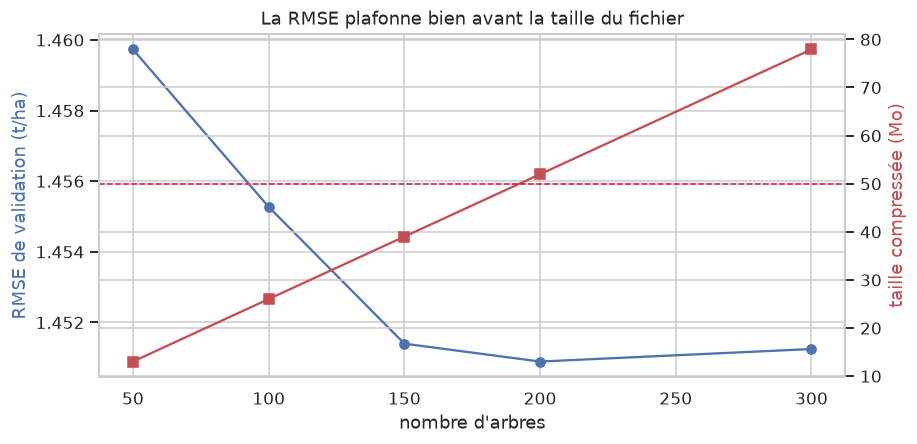

meilleure RMSE toutes tailles confondues : 1.4509 t/ha (200 arbres, 52.0 Mo)
-> au-delà de la limite de 50 Mo : inutilisable comme modèle servi

modèle retenu : 150 arbres, 39.0 Mo, RMSE 1.4514 t/ha
   écart à la meilleure RMSE : +0.0005 t/ha (0.03%)


In [9]:
fig, ax1 = plt.subplots(figsize=(8.5, 4.2))
ax1.plot(sizes["arbres"], sizes["RMSE CV"], marker="o", color="#4C72B0", label="RMSE")
ax1.set_xlabel("nombre d'arbres")
ax1.set_ylabel("RMSE de validation (t/ha)", color="#4C72B0")
ax2 = ax1.twinx()
ax2.plot(sizes["arbres"], sizes["taille lzma (Mo)"], marker="s", color="#C44E52")
ax2.axhline(50, ls="--", c="crimson", lw=1, label="limite 50 Mo")
ax2.set_ylabel("taille compressée (Mo)", color="#C44E52")
ax1.set_title("La RMSE plafonne bien avant la taille du fichier")
utils.save_figure("10_taille_modele")
plt.show()

LIMIT_MB = 50
best_value = sizes["RMSE CV"].min()
fits = sizes[sizes["taille lzma (Mo)"] < LIMIT_MB]
selected = fits.loc[fits["RMSE CV"].idxmin()]
print(f"meilleure RMSE toutes tailles confondues : {best_value:.4f} t/ha "
      f"({int(sizes.loc[sizes['RMSE CV'].idxmin(), 'arbres'])} arbres, "
      f"{sizes.loc[sizes['RMSE CV'].idxmin(), 'taille lzma (Mo)']:.1f} Mo)")
print(f"-> au-delà de la limite de {LIMIT_MB} Mo : inutilisable comme modèle servi")
print()
print(f"modèle retenu : {int(selected['arbres'])} arbres, {selected['taille lzma (Mo)']:.1f} Mo, "
      f"RMSE {selected['RMSE CV']:.4f} t/ha")
print(f"   écart à la meilleure RMSE : {selected['RMSE CV'] - best_value:+.4f} t/ha "
      f"({(selected['RMSE CV'] / best_value - 1):.2%})")

**Observations :**

- **La RMSE atteint son plancher bien avant que le fichier cesse de grossir.** Entre 150 et
  300 arbres, elle ne bouge plus qu'à la quatrième décimale, tandis que le fichier double
  puis triple.
- **C'est la limite de 50 Mo qui tranche, pas un seuil de performance.** Le minimum absolu
  de RMSE est atteint à 200 arbres — mais ce modèle pèse 52 Mo et serait inutilisable comme
  fichier versionné. **150 arbres est le plus gros modèle qui tient**, et il est à 0,03 % de
  l'optimum : la contrainte de livraison ne coûte donc rien de mesurable.
- La compression **`lzma`** est nettement plus efficace que le `zlib` par défaut de joblib
  sur une forêt, dont les arbres se ressemblent beaucoup.
- Un contrôle automatique (`yield_model.main`) fait échouer la sauvegarde si le fichier
  dépasse la limite.

# 5. Ce que le modèle utilise

L'importance par permutation mesure ce que le modèle perd quand une variable est mélangée :
c'est son usage réel, pas un effet de cause à effet.

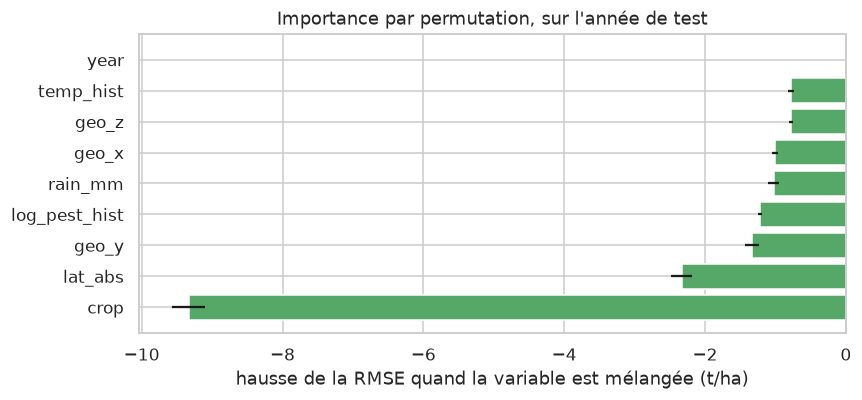

,variable,hausse de la RMSE,écart-type
2,year,-0.0000,0.0000
3,temp_hist,-0.7751,0.0449
8,geo_z,-0.7769,0.0321
6,geo_x,-1.0084,0.0419
1,rain_mm,-1.0256,0.0765
4,log_pest_hist,-1.2204,0.0322
7,geo_y,-1.3348,0.0958
5,lat_abs,-2.3298,0.1506
0,crop,-9.3341,0.2330


In [10]:
X_train, X_test, y_train, y_test = protocol.temporal_split(
    df, ym.VARIABLES, features.YIELD_TARGET)
final = ym.selected_model(n_trees=150).fit(X_train, y_train)

perm = permutation_importance(final, X_test, y_test, n_repeats=5,
                              random_state=config.SEED, scoring="neg_root_mean_squared_error")
importances = pd.DataFrame({
    "variable": ym.VARIABLES,
    "hausse de la RMSE": -perm.importances_mean,
    "écart-type": perm.importances_std,
}).sort_values("hausse de la RMSE", ascending=False)

fig, ax = plt.subplots(figsize=(8, 3.8))
ax.barh(importances["variable"][::-1], importances["hausse de la RMSE"][::-1],
        xerr=importances["écart-type"][::-1], color="#55A868")
ax.set_xlabel("hausse de la RMSE quand la variable est mélangée (t/ha)")
ax.set_title("Importance par permutation, sur l'année de test")
utils.save_figure("10_importance_recommend")
plt.show()
importances.round(4)

In [11]:
# `year` cannot be shuffled within a single test year: we retrain without it.
without_year = [v for v in ym.VARIABLES if v != "year"]
model_without_year = ym.pipeline(
    ExtraTreesRegressor(n_estimators=150, max_features=0.9, min_samples_split=3,
                        random_state=config.SEED, n_jobs=1)
).fit(X_train[without_year], y_train)

with_it = evaluation.metrics(y_test, final.predict(X_test))
without_it = evaluation.metrics(y_test, model_without_year.predict(X_test[without_year]))
print(f"avec `year` : RMSE {with_it['test_rmse']:.4f} t/ha | R² {with_it['test_r2']:.4f}")
print(f"sans `year` : RMSE {without_it['test_rmse']:.4f} t/ha | R² {without_it['test_r2']:.4f}")
print(f"-> coût du retrait : {without_it['test_rmse'] - with_it['test_rmse']:+.4f} t/ha")

avec `year` : RMSE 1.7115 t/ha | R² 0.9616
sans `year` : RMSE 2.0808 t/ha | R² 0.9433
-> coût du retrait : +0.3693 t/ha


**Observations :**

- **La culture pèse de loin le plus** : c'est la variable même du classement, et c'est bien
  ce qu'on attend d'un modèle de recommandation.
- **La géographie vient ensuite.** Elle porte en partie l'information du pays, sans lui
  donner d'identifiant — c'est le compromis assumé au notebook 09.
- Les conditions climatiques et les pesticides suivent, plus loin derrière.
- **`year` ne se mesure pas par permutation** sur une seule année de test : toutes les lignes
  y portent la même valeur. Le modèle réappris sans elle le montre directement.

Ces importances décrivent **l'usage des variables par le modèle**, pas des effets
agronomiques : pluie, température, pesticides et géographie sont toutes des valeurs
nationales, et portent en partie la même information.

# 6. Évaluation finale sur 2013

2013 n'a servi à aucun choix de modèle, de variable ni de réglage. Elle est touchée ici pour
la première et unique fois.

In [12]:
result = ym.train(df, n_trees=150)

apprentissage : 14,905 lignes (1991-2012)
test          : 700 lignes (2013)

validation temporelle    : RMSE 1.4514 ± 0.1318 t/ha | MAE 0.7252 t/ha | R² 0.9705
validation hors pays     : RMSE 4.0634 ± 0.4836 t/ha | MAE 2.4363 t/ha | R² 0.7201
test 2013                : RMSE 1.7115 t/ha | MAE 0.7894 t/ha | R² 0.9616

                                                     top1   top3  spearman  regret  relative_regret  groups
10 cultures FAO, rendement brut (t/ha)              0.948  1.000     0.957   0.151            0.009     116
10 cultures FAO, matière sèche (t/ha)               0.810  0.983     0.913   0.170            0.030     116
4 cultures de l'application, matière sèche (t/ha)   0.915  1.000     0.937   0.040            0.010     106
10 cultures FAO, produit brut (USD/ha)              0.940  0.991     0.964  37.963            0.005     116
4 cultures de l'application, produit brut (USD/ha)  0.896  1.000     0.863  14.454            0.017     106


In [13]:
validation, outside = result.cv, result.country_cv

pd.DataFrame({
    "RMSE (t/ha)": [validation["cv_rmse_mean"], outside["cv_rmse_mean"], result.scores["test_rmse"]],
    "MAE (t/ha)": [validation["cv_mae_mean"], outside["cv_mae_mean"], result.scores["test_mae"]],
    "R²": [validation["cv_r2_mean"], outside["cv_r2_mean"], result.scores["test_r2"]],
}, index=["Validation temporelle 2008-2012", "Validation hors pays (pays jamais vus)",
          "Test final 2013 (jamais utilisé)"]).round(4)


,RMSE (t/ha),MAE (t/ha),R²
Validation temporelle 2008-2012,1.4514,0.7252,0.9705
Validation hors pays (pays jamais vus),4.0634,2.4363,0.7201
Test final 2013 (jamais utilisé),1.7115,0.7894,0.9616


In [14]:
ym.save(result, df)
ym.log(result)
print(f"modèle servi : {config.YIELD_MODEL_PATH.stat().st_size / 1024**2:.1f} Mo")


modèle servi : 39.0 Mo


**Observations :**

- Le test 2013 est **cohérent avec la validation**, légèrement moins bon — ce qui était
  attendu : l'erreur augmentait déjà d'une année de validation à la suivante.
- Le classement reste de très bonne qualité sur cette année inédite.
- **Limite à énoncer** : toutes les lignes de 2013 portent sur des couples pays × culture
  déjà observés. La capacité du modèle à recommander une culture *nouvelle* pour un pays
  n'est donc **pas mesurée** par ce test.

# 7. Le service, tel qu'il répondra

In [15]:
import lzma, pickle
with lzma.open(config.YIELD_MODEL_PATH, "rb") as f:
    served = pickle.load(f)

print("cultures exclues du classement :", ", ".join(ym.EXCLUDED_CROPS), "\n")
columns = ["crop", "raw_yield_t_ha", "dry_matter_t_ha", "group",
            "price_usd_t", "price_source", "gross_product_usd_ha", "observed"]
for iso3 in ("FRA", "IND", "BRA"):
    context = ym.country_context(df, iso3)
    ranking = ym.ranking(served, context, ym.crops_of_country(df, iso3), prices=prices)
    print(f"=== {iso3} — conditions {context['year']} "
          f"(temp. moy. 3 ans {context['temp_hist']:.1f} °C, pluie {context['rain_mm']:.0f} mm)")
    print(ranking[columns].round(2).to_string(index=False))
    print()

cultures exclues du classement : Barley, Cotton 

=== FRA — conditions 2013 (temp. moy. 3 ans 11.3 °C, pluie 867 mm)
   crop  raw_yield_t_ha  dry_matter_t_ha            group  price_usd_t price_source  gross_product_usd_ha  observed
  Maize            9.23             8.03          cereale        247.0         pays               2279.44      True
  Wheat            7.03             6.11          cereale        246.4         pays               1731.49      True
   Rice            5.59             4.86          cereale        356.8         pays               1994.35      True
Soybean            2.81             2.53 oleoproteagineux        552.1         pays               1553.20      True

=== IND — conditions 2013 (temp. moy. 3 ans 26.2 °C, pluie 1083 mm)
   crop  raw_yield_t_ha  dry_matter_t_ha            group  price_usd_t     price_source  gross_product_usd_ha  observed
   Rice            3.46             3.01          cereale        377.3 médiane mondiale               1304.18     

**Observations :** le classement rendu porte tout ce dont l'interface a besoin pour être
honnête : le rendement brut, la matière sèche et le produit brut, le groupe agronomique, la
provenance du prix (le pays lui-même ou la médiane mondiale), et la mention de savoir si la
culture est réellement pratiquée dans le pays. L'orge et le coton n'y figurent plus : leur rang
n'aurait été qu'une copie de celui du blé et du sorgho.

L'ordre change d'un pays à l'autre: c'est bien un classement contextuel, et non une table
figée.

# Conclusion

## Le classement, rendu utilisable
Un classement en tonnes brutes place un tubercule en tête presque partout : l'écart avec les
céréales est surtout de l'eau. Le classement est donc rendu **en matière sèche** et par
**groupe agronomique**. Les cultures jamais produites dans le pays sont **signalées**. L'orge et
le coton, absents du jeu FAO, sont **exclus** du classement : leur rang n'aurait été qu'une copie
de celui du blé et du sorgho.

## Le classement servi, mesuré pour lui-même
Sur les quatre cultures de l'application (maïs, blé, riz, soja), en validation : la meilleure
culture est en tête dans **92 %** des cas en matière sèche et **93 %** en produit brut, contre
65 % pour un ordre figé. Suivre le modèle coûte en moyenne **1,3 %** du produit brut de la
meilleure culture, contre 11,8 % pour l'ordre figé. Le chiffre de 93 % du notebook 09, mesuré en
tonnes brutes sur dix cultures, ne décrivait pas ce que voit l'utilisateur.

## La lecture économique
Les **prix au producteur FAOSTAT** donnent un **produit brut** en USD/ha : la réponse la plus
proche de « la culture la plus rentable » que ces données permettent. Il se calcule sur les
quatre cultures de l'application: sur dix, l'igname extrapolée et valorisée au prix mondial
prend la tête de 68 pays qui n'en cultivent pas. Il est sensible aux prix : pour un pays sur
deux, ±20 % de prix suffit à changer la première culture. Les prix doivent donc être affichés
et modifiables, et le service présente les deux ou trois premières cultures.

## Le modèle servi
**`ExtraTrees` à 150 arbres**, compressé en `lzma` pour tenir sous la limite de 50 Mo. La RMSE
plafonne bien avant la taille du fichier : les arbres supplémentaires ne coûtaient que des
mégaoctets. Test final 2013 : RMSE 1,71 t/ha, R² 0,96.

## Ce que le modèle utilise
La **culture** d'abord (c'est la variable du classement) puis la **géographie**, puis les
conditions climatiques. `year` compte réellement, ce que seul un réapprentissage sans elle
permet de mesurer.

## Limites
1. Les conditions sont **nationales** : la pluie est une constante par pays, les pesticides un
   tonnage national qui dépend de la taille du pays. Le classement est un ordre de grandeur à
   l'échelle d'un pays, pas d'une parcelle.
2. Chaque pays ayant une position unique, un arbre **peut** s'en servir pour le reconnaître.
3. La recommandation d'une culture **nouvelle pour un pays** n'est pas mesurée par la
   validation.
4. Le **produit brut n'est pas une marge** : les coûts de production sont inconnus, et 57 % des
   prix utilisés sur dix cultures sont des médianes mondiales.
5. 117 pays et un historique s'arrêtant en 2013 : les autres pays ne peuvent pas être servis,
   et des campagnes récentes demanderaient des données à jour.